In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import os
from PIL import Image

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- input.jpg")
print("- Histogram_Comparison_Source_0.jpg")
print("- Histogram_Comparison_Source_1.jpg")
print("- Histogram_Comparison_Source_2.jpg")

Uploaded = files.upload()

for filename in Uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename
  print(f'{filename} Is Successfully Uploaded To "{dest}"')

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- input.jpg
- Histogram_Comparison_Source_0.jpg
- Histogram_Comparison_Source_1.jpg
- Histogram_Comparison_Source_2.jpg


Saving Histogram_Comparison_Source_0.jpg to Histogram_Comparison_Source_0.jpg
Saving Histogram_Comparison_Source_1.jpg to Histogram_Comparison_Source_1.jpg
Saving Histogram_Comparison_Source_2.jpg to Histogram_Comparison_Source_2.jpg
Saving input.jpg to input.jpg
Histogram_Comparison_Source_0.jpg Is Successfully Uploaded To "images/Histogram_Comparison_Source_0.jpg"
Histogram_Comparison_Source_1.jpg Is Successfully Uploaded To "images/Histogram_Comparison_Source_1.jpg"
Histogram_Comparison_Source_2.jpg Is Successfully Uploaded To "images/Histogram_Comparison_Source_2.jpg"
input.jpg Is Successfully Uploaded To "images/input.jpg"

Contents Of Images Folder:
[]


image1 Is:  (600, 800, 3)
image2 Is:  (300, 400, 3)


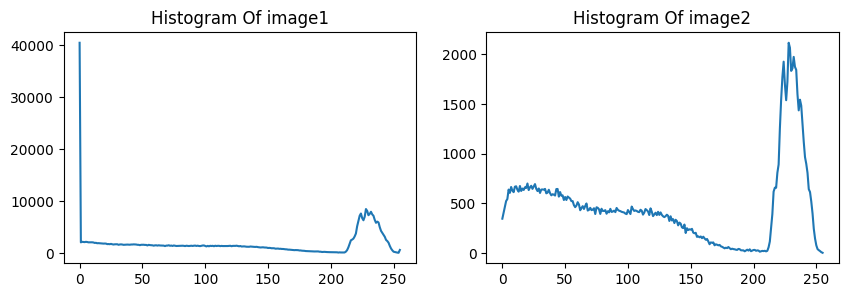

In [4]:
image1 = cv2.imread('input.jpg')

image2 = cv2.resize(image1, (image1.shape[1]//2, image1.shape[0]//2))

print("image1 Is: ", image1.shape)
print("image2 Is: ", image2.shape)

histogram1 = cv2.calcHist([image1], [0], None, [256], [0, 256])
histogram2 = cv2.calcHist([image2], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(histogram1)
plt.title('Histogram Of image1')

plt.subplot(1, 2, 2)
plt.plot(histogram2)
plt.title('Histogram Of image2')

plt.show()

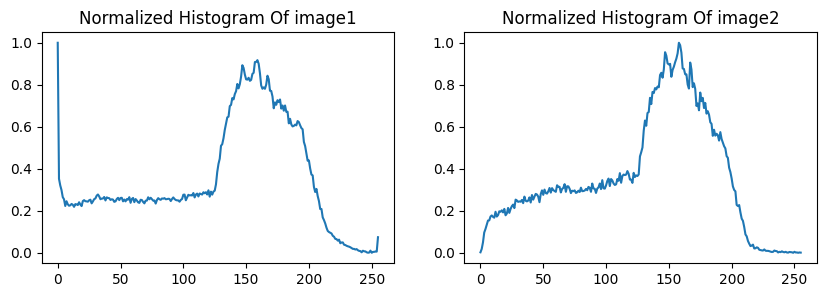

In [6]:
image1 = cv2.imread('input.jpg', 0)
image2 = cv2.resize(image1, (image1.shape[1]//2, image1.shape[0]//2))

histogram1 = cv2.calcHist([image1], [0], None, [256], [0, 256])
histogram2 = cv2.calcHist([image2], [0], None, [256], [0, 256])

histogram1_normalized = histogram1.copy()
histogram2_normalized = histogram2.copy()

cv2.normalize(histogram1, histogram1_normalized, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
cv2.normalize(histogram2, histogram2_normalized, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(histogram1_normalized)
plt.title('Normalized Histogram Of image1')

plt.subplot(1, 2, 2)
plt.plot(histogram2_normalized)
plt.title('Normalized Histogram Of image2')

plt.show()

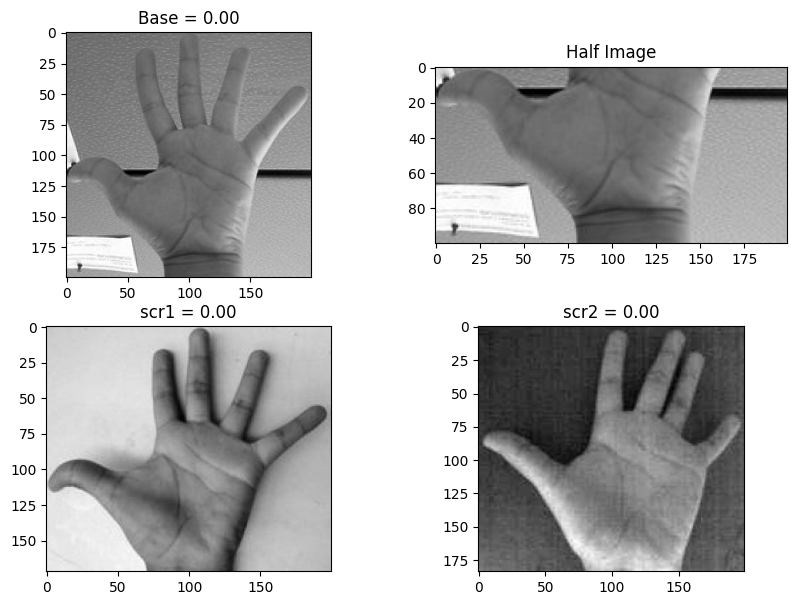

In [10]:
scr1 = cv2.imread('Histogram_Comparison_Source_0.jpg', 0)
scr2 = cv2.imread('Histogram_Comparison_Source_1.jpg', 0)
scr3 = cv2.imread('Histogram_Comparison_Source_2.jpg', 0)

hsv_base = cv2.cvtColor(scr1, cv2.COLOR_GRAY2BGR)
hsv_base = cv2.cvtColor(hsv_base, cv2.COLOR_BGR2HSV)

hsv_scr1 = cv2.cvtColor(cv2.cvtColor(scr2, cv2.COLOR_GRAY2BGR), cv2.COLOR_BGR2HSV)
hsv_scr2 = cv2.cvtColor(cv2.cvtColor(scr3, cv2.COLOR_GRAY2BGR), cv2.COLOR_BGR2HSV)

hsv_half_down = hsv_base[hsv_base.shape[0]//2:, :]

hist_base = cv2.calcHist([hsv_base], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_base, hist_base, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
hist_half_down = cv2.calcHist([hsv_half_down], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_half_down, hist_half_down, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

hist_scr1 = cv2.calcHist([hsv_scr1], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_scr1, hist_scr1, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
hist_scr2 = cv2.calcHist([hsv_scr2], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_scr2, hist_scr2, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

base_base = cv2.compareHist(hist_base, hist_base, cv2.HISTCMP_BHATTACHARYYA)
base_half_down = cv2.compareHist(hist_base, hist_half_down, cv2.HISTCMP_BHATTACHARYYA)
base_scr1 = cv2.compareHist(hist_base, hist_scr1, cv2.HISTCMP_BHATTACHARYYA)
base_scr2 = cv2.compareHist(hist_base, hist_scr2, cv2.HISTCMP_BHATTACHARYYA)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(scr1, cmap='gray')
plt.title(f'Base = {base_base:.2f}')

plt.subplot(2, 2, 2)
plt.imshow(cv2.cvtColor(hsv_half_down, cv2.COLOR_HSV2RGB))
plt.title('Half Image')

plt.subplot(2, 2, 3)
plt.imshow(scr2, cmap='gray')
plt.title(f'scr1 = {base_scr1:.2f}')

plt.subplot(2, 2, 4)
plt.imshow(scr3, cmap='gray')
plt.title(f'scr2 = {base_scr2:.2f}')

plt.show()

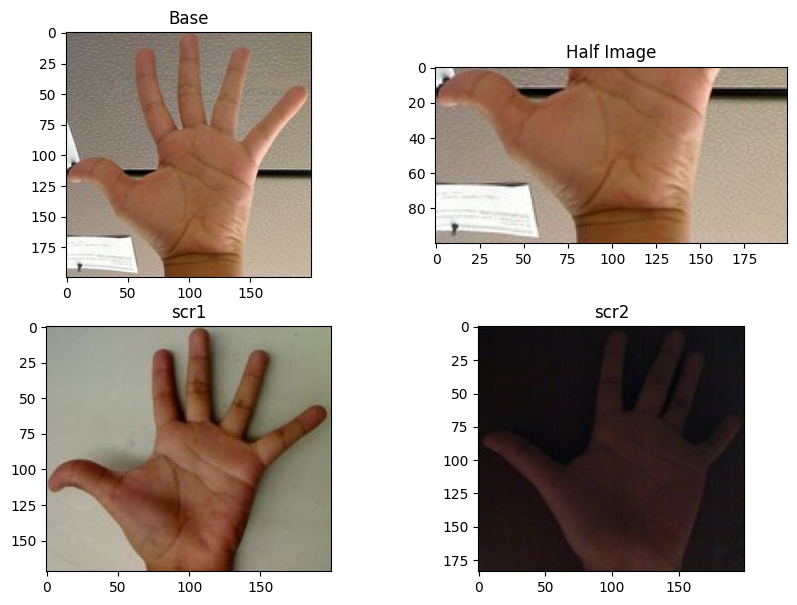

Method: BHATTACHARYYA
 -Perfect: 0.0, 
 -Base-Half:0.3106651880104802, 
 -Base-Test(1):0.7498451093056697, 
 -Base-Test(2) :0.9464567389602986
---
Method: CORREL
 -Perfect: 1.0, 
 -Base-Half:0.8263068078730407, 
 -Base-Test(1):0.0820323152728836, 
 -Base-Test(2) :0.02074296934219765
---
Method: CHISQR
 -Perfect: 0.0, 
 -Base-Half:34.033593851598084, 
 -Base-Test(1):661.1060186682498, 
 -Base-Test(2) :1712.5495483048298
---
Method: INTERSECT
 -Perfect: 92.59259354695678, 
 -Base-Half:46.73931341874413, 
 -Base-Test(1):11.652202861383557, 
 -Base-Test(2) :4.535974983125925
---
Method: KL_DIV
 -Perfect: 0.0, 
 -Base-Half:180.49322003660623, 
 -Base-Test(1):653.7298110863732, 
 -Base-Test(2) :1676.0983346142905
---


In [12]:
scr1 = cv2.imread('Histogram_Comparison_Source_0.jpg')
scr2 = cv2.imread('Histogram_Comparison_Source_1.jpg')
scr3 = cv2.imread('Histogram_Comparison_Source_2.jpg')

hsv_base = cv2.cvtColor(scr1, cv2.COLOR_BGR2HSV)
hsv_scr1 = cv2.cvtColor(scr2, cv2.COLOR_BGR2HSV)
hsv_scr2 = cv2.cvtColor(scr3, cv2.COLOR_BGR2HSV)

hsv_half_down = hsv_base[hsv_base.shape[0]//2:, :]

hist_base = cv2.calcHist([hsv_base], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_base, hist_base, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
hist_half_down = cv2.calcHist([hsv_half_down], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_half_down, hist_half_down, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
hist_scr1 = cv2.calcHist([hsv_scr1], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_scr1, hist_scr1, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
hist_scr2 = cv2.calcHist([hsv_scr2], [0, 1], None, [180, 256], [0, 180, 0, 256])
cv2.normalize(hist_scr2, hist_scr2, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(scr1[..., ::-1])
plt.title('Base')

plt.subplot(2, 2, 2)
plt.imshow(cv2.cvtColor(hsv_half_down, cv2.COLOR_HSV2RGB))
plt.title('Half Image')

plt.subplot(2, 2, 3)
plt.imshow(scr2[..., ::-1])
plt.title('scr1')

plt.subplot(2, 2, 4)
plt.imshow(scr3[..., ::-1])
plt.title('scr2')

plt.show()

methods = [cv2.HISTCMP_BHATTACHARYYA, cv2.HISTCMP_CORREL, cv2.HISTCMP_CHISQR, cv2.HISTCMP_INTERSECT, cv2.HISTCMP_KL_DIV]
method_names = ['BHATTACHARYYA', 'CORREL', 'CHISQR', 'INTERSECT', 'KL_DIV']

for method, method_name in zip (methods, method_names):
  print("Method:", method_name)
  base_base = cv2.compareHist(hist_base, hist_base, method)
  base_half = cv2.compareHist(hist_base, hist_half_down, method)
  base_test1 = cv2.compareHist(hist_base, hist_scr1, method)
  base_test2 = cv2.compareHist(hist_base, hist_scr2, method)
  print(' -Perfect: {}, \n -Base-Half:{}, \n -Base-Test(1):{}, \n -Base-Test(2) :{}\n---'.format(\
            base_base, base_half, base_test1, base_test2))